In [171]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Leitura dos datasets

In [172]:
folder = 'dataset'
df_list = []
for file in os.listdir(folder):
    df_list.append(pd.read_csv(folder + '/' + file))

df_list[4]['LBXIN'] = pd.NA

C:\Users\mateu\AppData\Local\Temp\ipykernel_12444\3257509553.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_list[4]['LBXIN'] = pd.NA


In [173]:
# sets das colunas
columns_set = [set(df.columns) for df in df_list]

# conjuntos das colunas comuns a todos os datasets
cols = columns_set[0]
for col in columns_set[1:]:
    cols = cols.intersection(col)

cols = list(cols)

In [174]:
# juncao dos datasets
df_nhanes = pd.concat([df[cols] for df in df_list])

In [175]:
cols_paper = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH1",
    "INDFMPIR",
    "BMXBMI",
    "BMXWT",
    "BMXHT",
    "BMXWAIST",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TCARB",
    "DR1TTFAT",
    "DR1TSUGR",
    "DR1TFIBE",
    "DR1TCHOL",
    "DR1TALCO",
    "LBXGLU",
    "LBXTC",
    "LBDLDL",
    "LBXIN"
]

In [176]:
df_nhanes = df_nhanes[cols_paper]

# Pre Processamento

In [177]:
selected_features = ['DR1TALCO', 'DR1TTFAT', 'DR1TPROT', 'DR1TKCAL', 'RIDRETH1']

In [178]:
def pre_process(data: pd.DataFrame) -> pd.DataFrame:
    # Cria uma cópia para não alterar o DataFrame original por referência
    df = data.copy()

    # Separa colunas numéricas e categóricas
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

    # 1. IMPUTAÇÃO DE VALORES AUSENTES
    # Numéricas: Média se simétrica (|skew| <= 0.5), Mediana se assimétrica (|skew| > 0.5)
    for col in num_cols:
        if df[col].isnull().any():
            skewness = df[col].skew()
            if abs(skewness) > 0.5:
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mean())

    # Categóricas: Moda
    for col in cat_cols:
        if df[col].isnull().any():
            mode_val = df[col].mode()
            if not mode_val.empty:
                df[col] = df[col].fillna(mode_val[0])

    # 2. REMOÇÃO DE OUTLIERS (IQR PADRÃO)
    if num_cols:
        Q1 = df[num_cols].quantile(0.25)
        Q3 = df[num_cols].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Mantém apenas as linhas que estão dentro dos limites em TODAS as colunas numéricas
        mask = ~((df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)).any(axis=1)
        df = df[mask].reset_index(drop=True)

    # 3. ESCALONAMENTO COM STANDARDSCALER
    if num_cols and not df.empty:
        scaler = StandardScaler()
        df[num_cols] = scaler.fit_transform(df[num_cols])

    return df
    

In [179]:
df_processed = pre_process(df_nhanes)
df_nhanes_processed = df_processed[selected_features]

# K-Means

In [180]:
n_clusters = []
inertias = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=0).fit(df_nhanes_processed)

    n_clusters.append(i)
    inertias.append(km.inertia_)

Text(0.5, 1.0, 'Inércia em função do número de centróides')

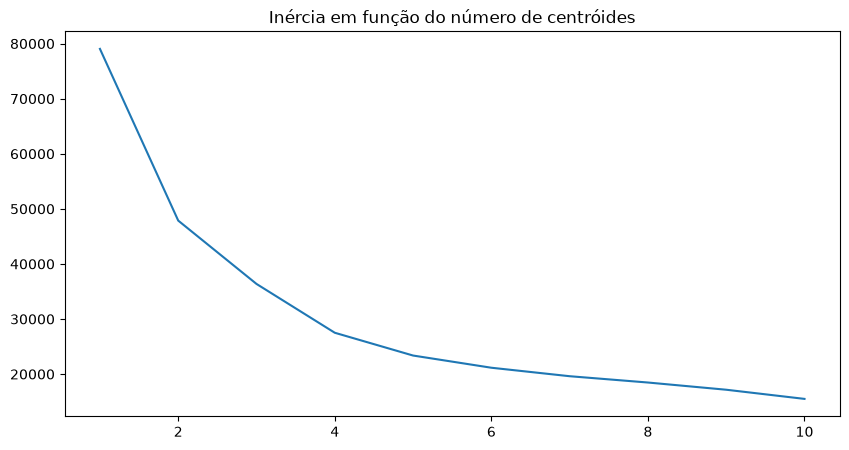

In [181]:
plt.figure(figsize=(10, 5))
plt.plot(n_clusters, inertias)
plt.title('Inércia em função do número de centróides')

## Avaliação do Modelo para n_centroides = 3 | Silhouette Score

In [182]:
model = KMeans(n_clusters=3, random_state=0)
df_nhanes_processed['clusters'] = model.fit_predict(df_nhanes_processed)
print(silhouette_score(df_nhanes_processed, df_nhanes_processed['clusters']))

0.41582994493827075


In [183]:
df_processed['clusters'] = df_nhanes_processed['clusters'].values

# Visualização dos Resultados

In [194]:
pca = PCA(2, random_state=42)
components = pca.fit_transform(df_processed.drop('clusters', axis=1))
x_axis = [c[0] for c in components]
y_axis = [c[1] for c in components]

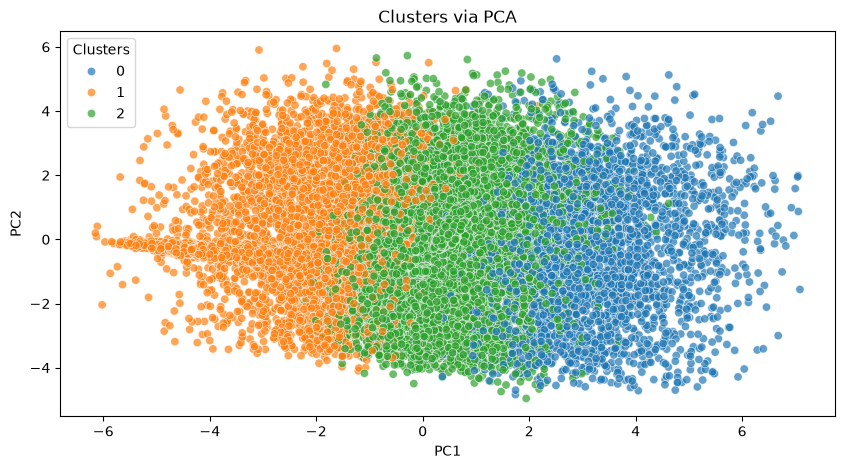

In [195]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    x=x_axis,
    y=y_axis,
    hue=df_nhanes_processed["clusters"],
    palette="tab10",
    alpha=0.7,
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clusters via PCA")
plt.legend(title="Clusters")
plt.show()

In [196]:
print(f"Variância explicada: {pca.explained_variance_ratio_.sum():.2%}")

Variância explicada: 48.88%
